[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/langchain-ai/langchain-academy/blob/main/module-1/chain.ipynb) [![在 LangChain Academy 中打开](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66e9eba12c7b7688aa3dbb5e_LCA-badge-green.svg)](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58238466-lesson-4-chain)

In [24]:
import json


def ppm(message):
    """Pretty print all details of a LangChain message."""
    data = {
        "type": message.__class__.__name__,
        "content": message.content,
        "additional_kwargs": message.additional_kwargs,
        "response_metadata": message.response_metadata,
        "id": message.id,
        "tool_calls": message.tool_calls if hasattr(message, "tool_calls") else [],
        "invalid_tool_calls": message.invalid_tool_calls
        if hasattr(message, "invalid_tool_calls")
        else [],
        "usage_metadata": dict(message.usage_metadata)
        if message.usage_metadata
        else None,
    }
    print(json.dumps(data, indent=2, default=str))


def ppms(messages):
    """Pretty print messages from LangChain (list) or LangGraph (dict with 'messages' key)."""
    # Handle LangGraph state dict
    if isinstance(messages, dict):
        messages = messages["messages"]

    # Handle single message object (not a list)
    if not isinstance(messages, list):
        messages = [messages]

    for i, msg in enumerate(messages):
        print(f"\n--- Message {i + 1} ---")

        # Handle plain strings (e.g. raw prompt strings in a message list)
        if isinstance(msg, str):
            print(f"Type: str")
            print(f"Content: {msg}")
            continue

        print(f"Type: {msg.__class__.__name__}")
        print(f"ID: {msg.id}")

        if hasattr(msg, "content") and msg.content:
            print(f"Content: {msg.content}")

        if hasattr(msg, "tool_calls") and msg.tool_calls:
            print("Tool Calls:")
            for tc in msg.tool_calls:
                print(f"  - name: {tc['name']}")
                print(f"    args: {tc['args']}")

        if hasattr(msg, "name"):
            print(f"Tool Name: {msg.name}")

        if hasattr(msg, "usage_metadata") and msg.usage_metadata:
            print("Usage:")
            print(msg.usage_metadata)

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎯 Chain

**一句话定位**:在上一节 node/edge 基础上，把 4 个概念拼成一条简单 chain。

**回顾**:上一节搭了带 node、普通 edge、conditional edge 的简单图。

**本节目标**：
- 用 [chat messages](https://docs.langchain.com/oss/python/langchain/messages) 作为 graph state
- 在 graph node 里使用 [chat model](https://docs.langchain.com/oss/python/integrations/chat)
- 给 chat model [绑定 tool](https://docs.langchain.com/oss/python/langchain/models#tool-calling)
- 在 graph node 里 [执行 tool call](https://docs.langchain.com/oss/python/langchain/models#tool-execution-loop)

![chain 结构图](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbab08dd607b08df5e1101_chain1.png)

</div>

## Messages

Chat model 用 [messages](https://docs.langchain.com/oss/python/langchain/messages) 表示对话里不同的角色。

LangChain 支持几种 message 类型：`HumanMessage`（用户发的）、`AIMessage`（模型回的）、`SystemMessage`（指示模型行为）、`ToolMessage`（tool 调用的结果）。

每条 message 可以带：

* `content` —— 消息内容
* `name` —— 可选，消息作者
* `response_metadata` —— 可选，元数据字典（通常由模型厂商在 `AIMessage` 里填充）

In [ ]:
from langchain_core.messages import AIMessage, HumanMessage

messages = [
    AIMessage(content=f"So you said you were researching ocean mammals?", name="Model")
]
messages.append(HumanMessage(content=f"Yes, that's right.", name="Lance"))
messages.append(
    AIMessage(content=f"Great, what would you like to learn about.", name="Model")
)
messages.append(
    HumanMessage(
        content=f"I want to learn about the best place to see Orcas in the US.",
        name="Lance",
    )
)

for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Model

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, that's right.
================================== Ai Message ==================================
Name: Model

Great, what would you like to learn about.
================================ Human Message =================================
Name: Lance

I want to learn about the best place to see Orcas in the US.


## Chat Models

Chat model 接收一串 message 作为输入。可选的[模型很多](https://docs.langchain.com/oss/python/integrations/chat)，这里用 OpenAI。

先确认 `OPENAI_API_KEY` 已设置，没设置的话会提示输入。

In [5]:
import os, getpass

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("OPENAI_API_KEY")

加载 chat model 后直接 `invoke` 一串 messages，返回的是带 `response_metadata` 的 `AIMessage`。

In [6]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o")
result = llm.invoke(messages)
type(result)

langchain_core.messages.ai.AIMessage

In [9]:
ppm(result)

{
  "type": "AIMessage",
  "content": "The best place to see orcas in the United States is the Pacific Northwest, specifically the waters around the San Juan Islands in Washington State. This area is renowned for its resident orca pods, which are part of the Southern Resident Killer Whales. The best times for viewing are generally from late spring to early autumn, with peak sightings typically between June and September.\n\nIn addition to the San Juan Islands, you can also spot orcas in other parts of the Puget Sound and along the coast of Washington State. Whale watching tours are popular in these areas and provide excellent opportunities to see orcas in their natural habitat.\n\nAnother notable location for orca sightings is in the waters around the coast of southeastern Alaska, although the resident orca population is not as large as that around the San Juan Islands.",
  "additional_kwargs": {
    "refusal": null
  },
  "response_metadata": {
    "token_usage": {
      "completion_t

## Tools

当你想让模型跟外部系统交互时，tool 就派上用场了。

外部系统（比如 API）往往要求特定的输入 schema，而不是自然语言。给模型 bind 一个 tool，相当于告诉它这个系统需要什么样的输入格式——模型会根据用户的自然语言输入，自己决定要不要调用这个 tool，调用时输出会符合 tool 的 schema。

[很多 LLM 厂商都支持 tool calling](https://docs.langchain.com/oss/python/integrations/chat)，LangChain 把[调用接口](https://blog.langchain.com/improving-core-tool-interfaces-and-docs-in-langchain/)做得很简单：直接把 Python 函数传给 `ChatModel.bind_tools(function)` 即可。

![tool calling 示意图](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbab08dc1c17a7a57f9960_chain2.png)

<div class="dark-info" style="background:#1e293b; color:#e2e8f0; padding:12px 24px; border-left:4px solid #60a5fa; border-radius:4px; width:97%;"><style>.dark-info strong{color:#fbbf24;}</style>

**🔑 核心心智模型**:`bind_tools` 不会让模型真正执行函数——模型只是"决定要调用哪个 tool、用什么参数"，返回一个结构化的 tool call，真正执行函数是我们自己的代码来做（见 ToolNode 环节）。

</div>

用一个简单例子演示 tool calling：`multiply` 函数就是我们的 tool。

In [11]:
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

llm_with_tools = llm.bind_tools([multiply])

传入 `"What is 2 multiplied by 3"` 这样的问题，模型会返回一个 tool call，参数跟函数签名对得上，还带着要调用的函数名：

```
{'arguments': '{"a":2,"b":3}', 'name': 'multiply'}
```

In [12]:
tool_call = llm_with_tools.invoke(
    [HumanMessage(content=f"What is 2 multiplied by 3", name="Lance")]
)

In [13]:
tool_call.tool_calls

[{'name': 'multiply',
  'args': {'a': 2, 'b': 3},
  'id': 'call_NoZJGETdy9Vuh80Tu6ZyrYQn',
  'type': 'tool_call'}]

## Using messages as state

有了上面这些基础，就可以把 [messages](https://docs.langchain.com/oss/python/langchain/overview#messages) 用作 graph state 了。

先定义 `MessagesState`：一个只有 `messages` 这个 key 的 `TypedDict`，`messages` 就是上面说的 message 列表。

In [14]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage

class MessagesState(TypedDict):
    messages: list[AnyMessage]

## Reducers

有个小问题：前面说过，每个 node 返回的新值会**覆盖**旧的 state 值。但对 `messages` 这个 key，我们想要的是**追加**，不是覆盖。

[Reducer 函数](https://docs.langchain.com/oss/python/langgraph/graph-api#reducers) 就是用来指定"state 更新时具体怎么合并"的。没指定 reducer 的话默认就是覆盖。

LangGraph 内置了 `add_messages` reducer，专门负责把新 message 追加到已有列表。只需要用 `Annotated` 给 `messages` key 标注这个 reducer 就行。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**关键洞察**:reducer 是 LangGraph state 更新语义的核心机制——不加 reducer 默认全覆盖，这是新手最容易踩的坑（比如以为 state 会自动合并列表,结果发现只保留了最后一次返回值）。

</div>

In [15]:
from typing import Annotated
from langgraph.graph.message import add_messages

class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

`messages` 列表作为 graph state 太常见了，LangGraph 直接内置了 [`MessagesState`](https://docs.langchain.com/oss/python/langgraph/graph-api#messagesstate)：

* 预置了一个 `messages` key
* 类型是 `list[AnyMessage]`
* 自带 `add_messages` reducer

比自己手写 `TypedDict` 更省事，之后基本都会直接用这个。

In [16]:
from langgraph.graph import MessagesState

class MessagesState(MessagesState):
    # Add any keys needed beyond messages, which is pre-built 
    pass

再往下深挖一层，看看 `add_messages` reducer 单独运行时是怎么工作的。

In [17]:
# Initial state
initial_messages = [
    AIMessage(content="Hello! How can I assist you?", name="Model"),
    HumanMessage(
        content="I'm looking for information on marine biology.", name="Lance"
    ),
]

# New message to add
new_message = AIMessage(
    content="Sure, I can help with that. What specifically are you interested in?",
    name="Model",
)

# Test
add_messages(initial_messages, new_message)

[AIMessage(content='Hello! How can I assist you?', additional_kwargs={}, response_metadata={}, name='Model', id='0ad8ca8d-13bc-45bd-a46f-7336d5a15b20', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="I'm looking for information on marine biology.", additional_kwargs={}, response_metadata={}, name='Lance', id='8e97377a-ffaf-48f9-a076-fa37e64a9cdd'),
 AIMessage(content='Sure, I can help with that. What specifically are you interested in?', additional_kwargs={}, response_metadata={}, name='Model', id='90c38453-27b8-4756-beca-aec937e0477d', tool_calls=[], invalid_tool_calls=[])]

## Our graph

现在把 `MessagesState` 用到图里。

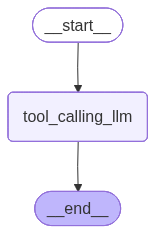

In [18]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

from langgraph.graph import MessagesState

class MessagesState(MessagesState):
    # Add any keys needed beyond messages, which is pre-built 
    pass
    
# Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_edge(START, "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

传入 `Hello!`，LLM 判断不需要调用任何 tool，直接回复。

In [19]:
messages = graph.invoke({"messages": HumanMessage(content="Hello!")})
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hello!
================================== Ai Message ==================================

Hello! How can I assist you today?


In [26]:
messages

{'messages': [HumanMessage(content='Hello!', additional_kwargs={}, response_metadata={}, id='b54abb01-62a6-41b5-adb2-f44d415e494a'),
  AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 54, 'total_tokens': 64, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_5dcbd0db7f', 'id': 'chatcmpl-Db63q91ao1S5iRZxXZnPMwRDgw4xn', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019de931-25bb-7143-a333-cb5e7067bfd2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 54, 'output_tokens': 10, 'total_tokens': 64, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details'

In [25]:
ppms(messages)


--- Message 1 ---
Type: HumanMessage
ID: b54abb01-62a6-41b5-adb2-f44d415e494a
Content: Hello!
Tool Name: None

--- Message 2 ---
Type: AIMessage
ID: lc_run--019de931-25bb-7143-a333-cb5e7067bfd2-0
Content: Hello! How can I assist you today?
Tool Name: None
Usage:
{'input_tokens': 54, 'output_tokens': 10, 'total_tokens': 64, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}


当模型判断输入/任务需要某个 tool 提供的功能时，才会选择调用它——不是每次都会触发 tool call。

In [ ]:
messages = graph.invoke({"messages": HumanMessage(content="Multiply 2 and 3")})
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

Multiply 2 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_Yk1a8zVXV2caus5NkgdkW68s)
 Call ID: call_Yk1a8zVXV2caus5NkgdkW68s
  Args:
    a: 2
    b: 3
